In [1]:
"""
Code for reproducing results for Who's Got Your Mail (IMC 21)
"""

# ============================================================================
# Import Required Libraries
# ============================================================================
import os
from functools import partial
import sys
import subprocess
import argparse
import itertools
from collections import defaultdict, Counter
import time
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
import numpy as np
import matplotlib
import warnings
import csv

In [2]:
# ============================================================================
# Configuration and Global Variables
# ============================================================================

# Suppress matplotlib warnings for cleaner output
warnings.filterwarnings("ignore")

# Configure matplotlib to use Type 42 fonts for better PDF compatibility
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Output directory for generated graphs
OUTPUT_PATH = "./graphs/"

# Marker styles for different companies in plots
MARKERS = [".", "o", "v", "p", "*", "s", "x", "2", "D"]

# Delimiter string indicating where company data begins in input files
STR_WHERE_COMPANY_DATA_STARTS_IN_OUTPUT = "Companys and Market Share (cleaned)"

# Default color palette for plotting
DEFAULT_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', 
                  '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

# Mapping of date strings to numeric indices for time series data
date_to_index = {
    "2017-06-08": 0, "2017-12-05": 1, "2018-06-05": 2, "2018-12-04": 3,
    "2019-06-06": 4, "2019-12-10": 5, "2020-06-09": 6, "2020-12-05": 7,
    "2021-06-08": 8,
}

# Reverse mapping for converting indices back to dates
index_to_date = {v: k for k, v in date_to_index.items()}

# Global index counter for subplot positioning (row-major order in 3x3 grid)
INDEX = 0

# ============================================================================
# Color and Marker Assignment Configuration
# ============================================================================

# Predefined color assignments for major companies to maintain consistency
# across all visualizations. Colors are in hex format.
COLOR_MAP = {
    "Google": '#1f77b4',      # Blue
    "Microsoft": '#ff7f0e',   # Orange
    "Mimecast": '#2ca02c',    # Green
    "ProofPoint": '#d62728',  # Red
    "Total": '#8c564b',       # Brown (for aggregated totals)
    "Self": '#e377c2',        # Pink (for self-hosted servers)
    "Yandex": '#9467bd',      # Purple
    "Barracuda": '#9467bd',   # Purple (grouped with similar services)
    "GoDaddy": '#9467bd'      # Purple (grouped with similar services)
}

# Predefined marker shapes for major companies to maintain visual distinction
MARKER_MAP = {
    "Google": '.',        # Point
    "Microsoft": 'o',     # Circle
    "Mimecast": 'v',      # Triangle down
    "ProofPoint": 'p',    # Pentagon
    "Total": 'D',         # Diamond
    "Self": 's',          # Square
    "Yandex": 'x',        # X mark
    "Barracuda": 'x',     # X mark (grouped with similar services)
    "GoDaddy": 'x'        # X mark (grouped with similar services)
}

In [3]:
def get_next_color(comp, colors):
    """
    Get the designated color for a company and remove it from available colors.
    
    Args:
        comp (str): Company name
        colors (list): List of available colors to choose from
    
    Returns:
        str: Hex color code for the company
    """
    # Check if company has a predefined color
    if comp in COLOR_MAP:
        color = COLOR_MAP[comp]
        # Remove color from available pool if it exists
        if color in colors:
            colors.remove(color)
        return color
    # Fall back to next available color or default if pool is empty
    return colors.pop(0) if colors else DEFAULT_COLORS[0]

def get_next_marker(comp, markers):
    """
    Get the designated marker shape for a company and remove it from available markers.
    
    Args:
        comp (str): Company name
        markers (list): List of available marker shapes to choose from
    
    Returns:
        str: Marker shape character for the company
    """
    # Check if company has a predefined marker
    if comp in MARKER_MAP:
        marker = MARKER_MAP[comp]
        # Remove marker from available pool if it exists
        if marker in markers:
            markers.remove(marker)
        return marker
    # Fall back to next available marker or default if pool is empty
    return markers.pop(0) if markers else MARKERS[0]

# ============================================================================
# Data Reading and Processing
# ============================================================================

def read_top_company_data(mx_type, date_specified, topn, ttl_num_domains, version_info):
    """
    Read and parse company market share data from output files.
    
    This function reads processed certificate report output files and extracts
    company coverage statistics, including the number of domains using each
    email service provider.
    
    Args:
        mx_type (str): Type of domain dataset ('common', 'com_common', 'gov_common')
        date_specified (str): Date string in format 'YYYY-MM-DD'
        topn (int): Number of top companies to extract
        ttl_num_domains (dict): Total domain counts for each mx_type and date
        version_info (str): Version identifier for the data files
    
    Returns:
        tuple: (top_stats dict, real_topn_stats list)
            - top_stats: Dictionary mapping company names to coverage numbers
            - real_topn_stats: List of (company_name, coverage) tuples for top N
    """
    # Construct the input file path
    output_file_name = f"./data/cr_output_cr_{mx_type}_old_certs_{date_specified}_{version_info}"
    
    # Initialize data structures
    dict_provider_to_size = {}  # Company name -> coverage count
    top_stats = {}                # Final statistics dictionary
    real_topn_stats = []          # List of top N companies with coverage
    record = False                # Flag to start recording company data
    groundtruth = 0               # Total domains with responding SMTP servers

    # Parse the output file line by line
    with open(output_file_name) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            # Extract groundtruth count from metadata line
            if "with responding smtp server" in line:
                groundtruth += eval(line)[1]
                continue

            # Check if we've reached the company data section
            if line.startswith(STR_WHERE_COMPANY_DATA_STARTS_IN_OUTPUT):
                record = True
            elif record:
                try:
                    # Parse company data line (expected format: tuple with name, stats)
                    r = eval(line)
                    name, coverage, ases = r[0], r[1][1], r[1][-1]
                    
                    # Clean up AS number set (remove None values)
                    ases = ases - set([None])
                    
                    # Store coverage data
                    dict_provider_to_size[name] = float(coverage)
                    top_stats[name] = coverage
                    
                    # Build top N list (only store up to topn+1 entries)
                    if len(real_topn_stats) <= topn:
                        real_topn_stats.append((name, coverage))
                except:
                    # Re-raise exception with context for debugging
                    raise
    
    # Calculate total coverage and add metadata to stats
    ttl = sum(dict_provider_to_size.values())
    top_stats['total_good_id'] = groundtruth
    top_stats['total_domains'] = ttl_num_domains[mx_type][date_to_index[date_specified]]
    
    return top_stats, real_topn_stats

# ============================================================================
# Coordinate Transform Functions (for dual y-axes)
# ============================================================================

def forward(y, mx_type):
    """
    Convert absolute domain counts to percentages for secondary y-axis.
    
    Args:
        y (float): Absolute number of domains
        mx_type (str): Dataset type to determine total domain count
    
    Returns:
        float: Percentage value (0-100)
    """
    # Total domain counts for each dataset type
    ttl_map = {"common": 93538, "gov_common": 3496, "com_common": 580537}
    return y * 100.0 / ttl_map.get(mx_type, 1)

def inverse(y, mx_type):
    """
    Convert percentages back to absolute domain counts for secondary y-axis.
    
    Args:
        y (float): Percentage value (0-100)
        mx_type (str): Dataset type to determine total domain count
    
    Returns:
        float: Absolute number of domains
    """
    # Total domain counts for each dataset type
    ttl_map = {"common": 93538, "gov_common": 3496, "com_common": 580537}
    return y * ttl_map.get(mx_type, 1) / 100.0

# ============================================================================
# Company Data Aggregation
# ============================================================================

def aggregate_company_data(comp, data):
    """
    Aggregate data for companies that operate under multiple domain names.
    
    Many email service providers operate under multiple domains (e.g., ProofPoint
    uses pphosted.com, ppe-hosted.com, etc.). This function consolidates all
    domains belonging to a single company into a single coverage value.
    
    Args:
        comp (str): Company name to aggregate data for
        data (dict): Dictionary mapping domain names to coverage counts
    
    Returns:
        float: Total coverage count for the company across all its domains
    
    Raises:
        ValueError: If company is not found in data or aggregation map
    """
    # Map of company names to their associated domain names
    # Each company may operate email services under multiple domains
    aggregation_map = {
        "Mimecast": ['mimecast.com', 'mimecast.co.za', 'mimecast-offshore.com'],
        "ProofPoint": ["pphosted.com", "ppe-hosted.com", "ppops.net", "gpphosted.com"],
        "AppRiver": ['appriver.com', 'arsmtp.com', 'mimecast-offshore.com'],
        "Barracuda": ['barracudanetworks.com', 'barracuda.com'],
        "Cisco Ironport": ['iphmx.com', 'Cisco'],
        "GoDaddy": ["secureserver.net", "mailcore.me", "hosteurope.de", 
                    "extendcp.co.uk", "ispgateway.de"],
        "OVH": ["ovh.net", "ovh.ca"],
        "UnitedInternet": ["kundenserver.de", "perfora.net", "1and1.com", 
                           "mail.com", "livemail.co.uk", "web.de", "gmx.net"],
        "NameCheap": ["privateemail.com", "namecheap.tech", "registrar-servers.com",
                      "web-hosting.com", "namecheaphosting.com", "jellyfish.systems"],
        "Ukraine.ua": ["default-host.net", "ukraine.com.ua", "vps-ukraine.com.ua",
                       "vps-default-host.net"]
    }
    
    # If company exists directly in data (not aggregated), return its value
    if comp in data:
        return data[comp]
    
    # If company needs aggregation, sum all its domain values
    if comp in aggregation_map:
        return sum(data.get(domain, 0) for domain in aggregation_map[comp])
    
    # Company not found - this is an error condition
    raise ValueError(f"Company {comp} not found in data")

# ============================================================================
# Common Visualization Utilities
# ============================================================================

def setup_plot_axes(ax, mx_type, dates):
    """
    Configure common axes properties for all plots including dual y-axes.
    
    Sets up:
    - Primary y-axis (absolute domain counts)
    - Secondary y-axis (percentages)
    - X-axis labels (dates)
    - Grid and font sizes
    
    Args:
        ax (matplotlib.axes.Axes): The axes object to configure
        mx_type (str): Dataset type for percentage calculations
        dates (tuple): Tuple of date strings
    
    Returns:
        matplotlib.axes.Axes: The secondary y-axis object
    """
    func_forward = partial(forward, mx_type=mx_type)
    func_inverse = partial(inverse, mx_type=mx_type)
    
    secax = ax.secondary_yaxis('right', functions=(func_forward, func_inverse))
    secax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
    secax.tick_params(axis="y", labelsize=12)
    
    # Setup x-axis labels
    if len(dates) == 7:
        # For gov_common: create labels for all 9 positions but only show data for positions 2-8
        all_dates = [index_to_date[i][:7] for i in range(9)]
        ax.set_xticks(range(9))  # Set tick positions for all 9 dates
        ax.set_xticklabels(all_dates, rotation=45, fontsize=18)
        ax.set_xlim(-0.5, 8.5)  # Set x-axis limits to show all 9 positions
    else:
        xpoints = [index_to_date[i][:7] for i in range(len(dates))]
        ax.set_xticks(range(len(dates)))
        ax.set_xticklabels(xpoints, rotation=45, fontsize=18)
        ax.set_xlim(-0.5, len(dates) - 0.5)
    
    ax.grid(True)
    for tick in ax.yaxis.get_major_ticks():
        tick.label.set_fontsize(12)
    
    return secax

def get_mx_type_name(mx_type):
    """
    Convert mx_type code to human-readable display name.
    
    Args:
        mx_type (str): Internal dataset type identifier
    
    Returns:
        str: Display name for the dataset
    """
    name_map = {"common": "Alexa", "gov_common": "GOV", "com_common": "COM"}
    return name_map.get(mx_type, mx_type)



def plot_company_data(ax, dates, comps, all_stats, colors, markers, 
                      include_totals=True, include_self_hosted=False,
                      self_hosted_data=None):
    """Common plotting logic for company data."""
    ps = []
    ypoints_ttl = [0] * len(dates)
    
    # Determine x-axis positions based on date length
    if len(dates) == 7:
        # For gov_common: plot at positions 2-8 (corresponding to dates starting from 2018-06-05)
        xpoints = list(range(2, 9))
    else:
        # For common and com_common: plot at positions 0-8
        xpoints = list(range(len(dates)))
    
    # Plot individual companies
    for comp in comps:
        ypoints = []
        for i, d in enumerate(dates):
            num = aggregate_company_data(comp, all_stats[i])
            ypoints.append(num)
            ypoints_ttl[i] += num
        
        ypoints = np.array(ypoints)
        p, = ax.plot(xpoints, ypoints, 
                    marker=get_next_marker(comp, markers),
                    color=get_next_color(comp, colors))
        ps.append(p)
    
    # Plot totals
    if include_totals:
        p, = ax.plot(xpoints, ypoints_ttl, 
                    marker=get_next_marker("Total", markers),
                    color=get_next_color("Total", colors))
        ps.append(p)
    
    # Plot self-hosted
    if include_self_hosted and self_hosted_data:
        p, = ax.plot(xpoints, self_hosted_data,
                    marker=get_next_marker("Self", markers),
                    color=get_next_color("Self", colors))
        ps.append(p)
    
    return ps, xpoints

In [4]:
# Main Visualization Functions
def vis_result_top_company(mx_type, dates, topn, ttl_num_domains, version_info):
    """Visualize top companies."""
    global INDEX, FIG, AXES
    
    if mx_type not in ["common", "com_common", "gov_common"]:
        return
    
    colors = DEFAULT_COLORS.copy()
    markers = MARKERS.copy()
    
    # Read all data
    all_stats = []
    for date_specified in dates:
        top_stats, real_topn_stats = read_top_company_data(
            mx_type, date_specified, topn, ttl_num_domains, version_info)
        if date_specified == dates[-1]:
            recent_real_topn_stats = real_topn_stats
        all_stats.append(top_stats)
    
    # Get top companies
    if mx_type != "com_common":
        comps = [i[0] for i in recent_real_topn_stats][:topn]
    else:
        tmp = [i[0] for i in recent_real_topn_stats][:6]
        comps = tmp[:4] + tmp[5:6]
    
    print(f"Visualizing Top Companies\nTop Companies: {comps}")
    print(f'>>> Generating Graph for Top Companies in {mx_type}\n')
    
    # Self-hosted server data (hardcoded)
    self_hosted_map = {
        "common": [10898.63, 10642.07, 10259.94, 9695.68, 9063.13, 
                   9208.92, 8958.11, 8199.41, 7407.31],
        "gov_common": [356.0, 343.0, 305.0, 301.0, 279.0, 215.0, 189.0],
        "com_common": [3116.83, 2927.83, 2792.33, 2657.17, 2382.67, 
                       2316.17, 2246.17, 2017.5, 1836.33]
    }
    
    # Setup axes
    r, c = INDEX // 3, INDEX % 3
    ax = AXES[r, c]
    INDEX += 1
    
    # Plot data
    ps, xpoints = plot_company_data(
        ax, dates, comps, all_stats, colors, markers,
        include_totals=True, include_self_hosted=True,
        self_hosted_data=self_hosted_map.get(mx_type, [0]*len(dates))
    )
    
    # Setup axes and formatting
    setup_plot_axes(ax, mx_type, dates)
    
    # Legend
    legend_map = {
        "common": ["Google", "Microsoft", "Yandex", "ProofPoint", "Mimecast",
                   "Top5 Total", "Self-Hosted"],
        "com_common": ["GoDaddy", "Google", "Microsoft", "UnitedInternet", "OVH",
                       "Top5 Total", "Self-Hosted"],
        "gov_common": ["Microsoft", "Google", "Barracuda", "ProofPoint", "Mimecast",
                       "Top5 Total", "Self-Hosted"]
    }
    
    bbox_map = {"common": (1, 0.92), "com_common": (1, 0.94), "gov_common": (1, 0.894)}
    ax.legend(legend_map[mx_type], loc="upper right", 
             bbox_to_anchor=bbox_map.get(mx_type, (1, 0.9)), prop={'size': 12})
    
    # Title
    idx_letter = chr(ord("a") + INDEX - 1)
    mx_type_name = get_mx_type_name(mx_type)
    ax.set_title(f"({idx_letter}) Top Companies in {mx_type_name}", 
                fontweight='bold', fontsize=16)
    
    print('\n\n')

def vis_result_secure_services(mx_type, dates, topn, ttl_num_domains, version_info):
    """Visualize security service companies."""
    global INDEX, FIG, AXES
    
    # Read all data
    all_stats = []
    for date_specified in dates:
        top_stats, real_topn_stats = read_top_company_data(
            mx_type, date_specified, topn, ttl_num_domains, version_info)
        all_stats.append(top_stats)
    
    comps = ['ProofPoint', 'Mimecast', 'Barracuda', 'Cisco Ironport', 'AppRiver']
    print(f"Visualizing Top Security Companies\nTop Security Companies: {comps}")
    print(f'>>> Generating Graph for Top Security Companies in {mx_type}\n')
    
    # Setup axes
    r, c = INDEX // 3, INDEX % 3
    ax = AXES[r, c]
    INDEX += 1
    
    colors = DEFAULT_COLORS.copy()
    markers = MARKERS.copy()
    
    # Plot data
    ps, xpoints = plot_company_data(
        ax, dates, comps, all_stats, colors, markers,
        include_totals=True, include_self_hosted=False
    )
    
    # Setup axes and formatting
    setup_plot_axes(ax, mx_type, dates)
    
    # Legend
    bbox_map = {"common": (1, 0.82), "com_common": (1, 0.82), "gov_common": (1, 0.815)}
    ax.legend(comps + ["Total"], loc="upper right",
             bbox_to_anchor=bbox_map.get(mx_type, (1, 0.82)), prop={'size': 12})
    
    # Title
    idx_letter = chr(ord("a") + INDEX - 1)
    mx_type_name = get_mx_type_name(mx_type)
    ax.set_title(f"({idx_letter}) Popular E-mail Security Companies in {mx_type_name}",
                fontweight='bold', fontsize=16)
    
    print('\n\n')

def vis_result_webhosting_services(mx_type, dates, topn, ttl_num_domains, version_info):
    """Visualize web hosting service companies."""
    global INDEX, FIG, AXES
    
    # Read all data
    all_stats = []
    for date_specified in dates:
        top_stats, real_topn_stats = read_top_company_data(
            mx_type, date_specified, topn, ttl_num_domains, version_info)
        all_stats.append(top_stats)
    
    comps = ['GoDaddy', 'OVH', 'UnitedInternet', 'Ukraine.ua', 'NameCheap']
    print(f"Visualizing Top Web Hosting Companies\nTop Hosting Companies: {comps}")
    print(f'>>> Generating Graph for Top Hosting Companies in {mx_type}\n')
    
    # Setup axes
    r, c = INDEX // 3, INDEX % 3
    ax = AXES[r, c]
    INDEX += 1
    
    colors = DEFAULT_COLORS.copy()
    markers = MARKERS.copy()
    
    # Plot data
    ps, xpoints = plot_company_data(
        ax, dates, comps, all_stats, colors, markers,
        include_totals=True, include_self_hosted=False
    )
    
    # Setup axes and formatting
    setup_plot_axes(ax, mx_type, dates)
    
    # Legend
    bbox_map = {"common": (1, 0.75), "com_common": (1, 0.65), "gov_common": (1, 0.47)}
    ax.legend(comps + ["Total"], loc="upper right",
             bbox_to_anchor=bbox_map.get(mx_type, (1, 0.75)), prop={'size': 12})
    
    # Title
    idx_letter = chr(ord("a") + INDEX - 1)
    mx_type_name = get_mx_type_name(mx_type)
    ax.set_title(f"({idx_letter}) Popular Web Hosting Companies in {mx_type_name}",
                fontweight='bold', fontsize=16)
    
    print('\n\n')

def gen_all_graphs(ttl_num_domains, version_info, topn=5):
    """Generate all visualization graphs."""
    mx_configs = [
        ("common", ("2017-06-08", "2017-12-05", "2018-06-05", "2018-12-04",
                    "2019-06-06", "2019-12-10", "2020-06-09", "2020-12-05", "2021-06-08")),
        ("com_common", ("2017-06-08", "2017-12-05", "2018-06-05", "2018-12-04",
                        "2019-06-06", "2019-12-10", "2020-06-09", "2020-12-05", "2021-06-08")),
        ("gov_common", ("2018-06-05", "2018-12-04", "2019-06-06", "2019-12-10",
                        "2020-06-09", "2020-12-05", "2021-06-08"))
    ]
    
    for mx_type, dates in mx_configs:
        vis_result_top_company(mx_type, dates, topn, ttl_num_domains, version_info)
        vis_result_secure_services(mx_type, dates, topn, ttl_num_domains, version_info)
        vis_result_webhosting_services(mx_type, dates, topn, ttl_num_domains, version_info)

In [5]:
def read_all_company_data(mx_type, date_specified, version_info, ttl_num_domains=None, output_csv=None):
    """
    Read and parse all company data from output files.
    
    Args:
        mx_type: Type of MX record (common, gov_common, com_common)
        date_specified: Date string for the data file
        version_info: Version string for the data file
        ttl_num_domains: Dictionary with total number of domains for each mx_type
        output_csv: Optional path to save CSV file. If None, uses default naming.
    
    Returns:
        list: List of tuples (provider, domains_that_use_provider) sorted by domains_that_use_provider descending
    """
    output_file_name = f"./data/cr_output_cr_{mx_type}_old_certs_{date_specified}_{version_info}"
    all_providers = []
    record = False
    
    print(f"\nReading all company data from: {output_file_name}")
    print(f"MX Type: {mx_type}, Date: {date_specified}")
    
    # Print total domains if provided
    if ttl_num_domains and mx_type in ttl_num_domains:
        date_idx = date_to_index.get(date_specified)
        if date_idx is not None and date_idx < len(ttl_num_domains[mx_type]):
            total_domains = ttl_num_domains[mx_type][date_idx]
            print(f"Total domains with active and properly-configured mail servers: {total_domains:,}")
    print()
    
    try:
        with open(output_file_name) as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                
                if line.startswith(STR_WHERE_COMPANY_DATA_STARTS_IN_OUTPUT):
                    record = True
                    # print(f"Found company data section...")
                elif record:
                    try:
                        r = eval(line)
                        provider = r[0]
                        domains_that_use_provider = r[1][1]  # Get the domains_that_use_provider value
                        all_providers.append((provider, domains_that_use_provider))
                    except Exception as e:
                        # Stop reading when we hit non-parseable data
                        break
        
        # Sort by domains_that_use_provider (descending)
        all_providers.sort(key=lambda x: x[1], reverse=True)
        
        print(f"Total unique provider IDs found: {len(all_providers)}")
        print(f"Note that one company can own multiple provider IDs.")
        print(f"We split 1 credit if multiple primary MX records exist.\n")
        
        # Print top 10
        print("=" * 80)
        print(f"TOP 10 PROVIDERS for {mx_type} on {date_specified}")
        print("=" * 80)
        print(f"{'Rank':<6} {'Provider':<40} {'Domains that Use This Provider':>15}")
        print("-" * 80)
        for i, (provider, domains_that_use_provider) in enumerate(all_providers[:10], 1):
            print(f"{i:<6} {provider:<40} {domains_that_use_provider:>15,.2f}")
        print("=" * 80)
        print()
        
        # Save to CSV
        if output_csv is None:
            output_csv = f"./data/all_providers_{mx_type}_{date_specified}_{version_info}.csv"
        
        with open(output_csv, 'w', newline='', encoding='utf-8') as csvfile:
            writer = csv.writer(csvfile)
            writer.writerow(['Provider', 'Domains_of_Provider'])
            writer.writerows(all_providers)
        
        print(f"Data saved to: {output_csv}")
        print(f"Total rows written: {len(all_providers)}\n\n")
        
        return all_providers
        
    except FileNotFoundError:
        print(f"ERROR: File not found: {output_file_name}")
        return []
    except Exception as e:
        print(f"ERROR: {e}")
        return []

Visualizing Top Companies
Top Companies: ['Google', 'Microsoft', 'Yandex', 'ProofPoint', 'Mimecast']
>>> Generating Graph for Top Companies in common




Visualizing Top Security Companies
Top Security Companies: ['ProofPoint', 'Mimecast', 'Barracuda', 'Cisco Ironport', 'AppRiver']
>>> Generating Graph for Top Security Companies in common




Visualizing Top Web Hosting Companies
Top Hosting Companies: ['GoDaddy', 'OVH', 'UnitedInternet', 'Ukraine.ua', 'NameCheap']
>>> Generating Graph for Top Hosting Companies in common




Visualizing Top Companies
Top Companies: ['GoDaddy', 'Google', 'Microsoft', 'UnitedInternet', 'OVH']
>>> Generating Graph for Top Companies in com_common




Visualizing Top Security Companies
Top Security Companies: ['ProofPoint', 'Mimecast', 'Barracuda', 'Cisco Ironport', 'AppRiver']
>>> Generating Graph for Top Security Companies in com_common




Visualizing Top Web Hosting Companies
Top Hosting Companies: ['GoDaddy', 'OVH', 'UnitedInternet', 'Ukraine.ua', 'Nam

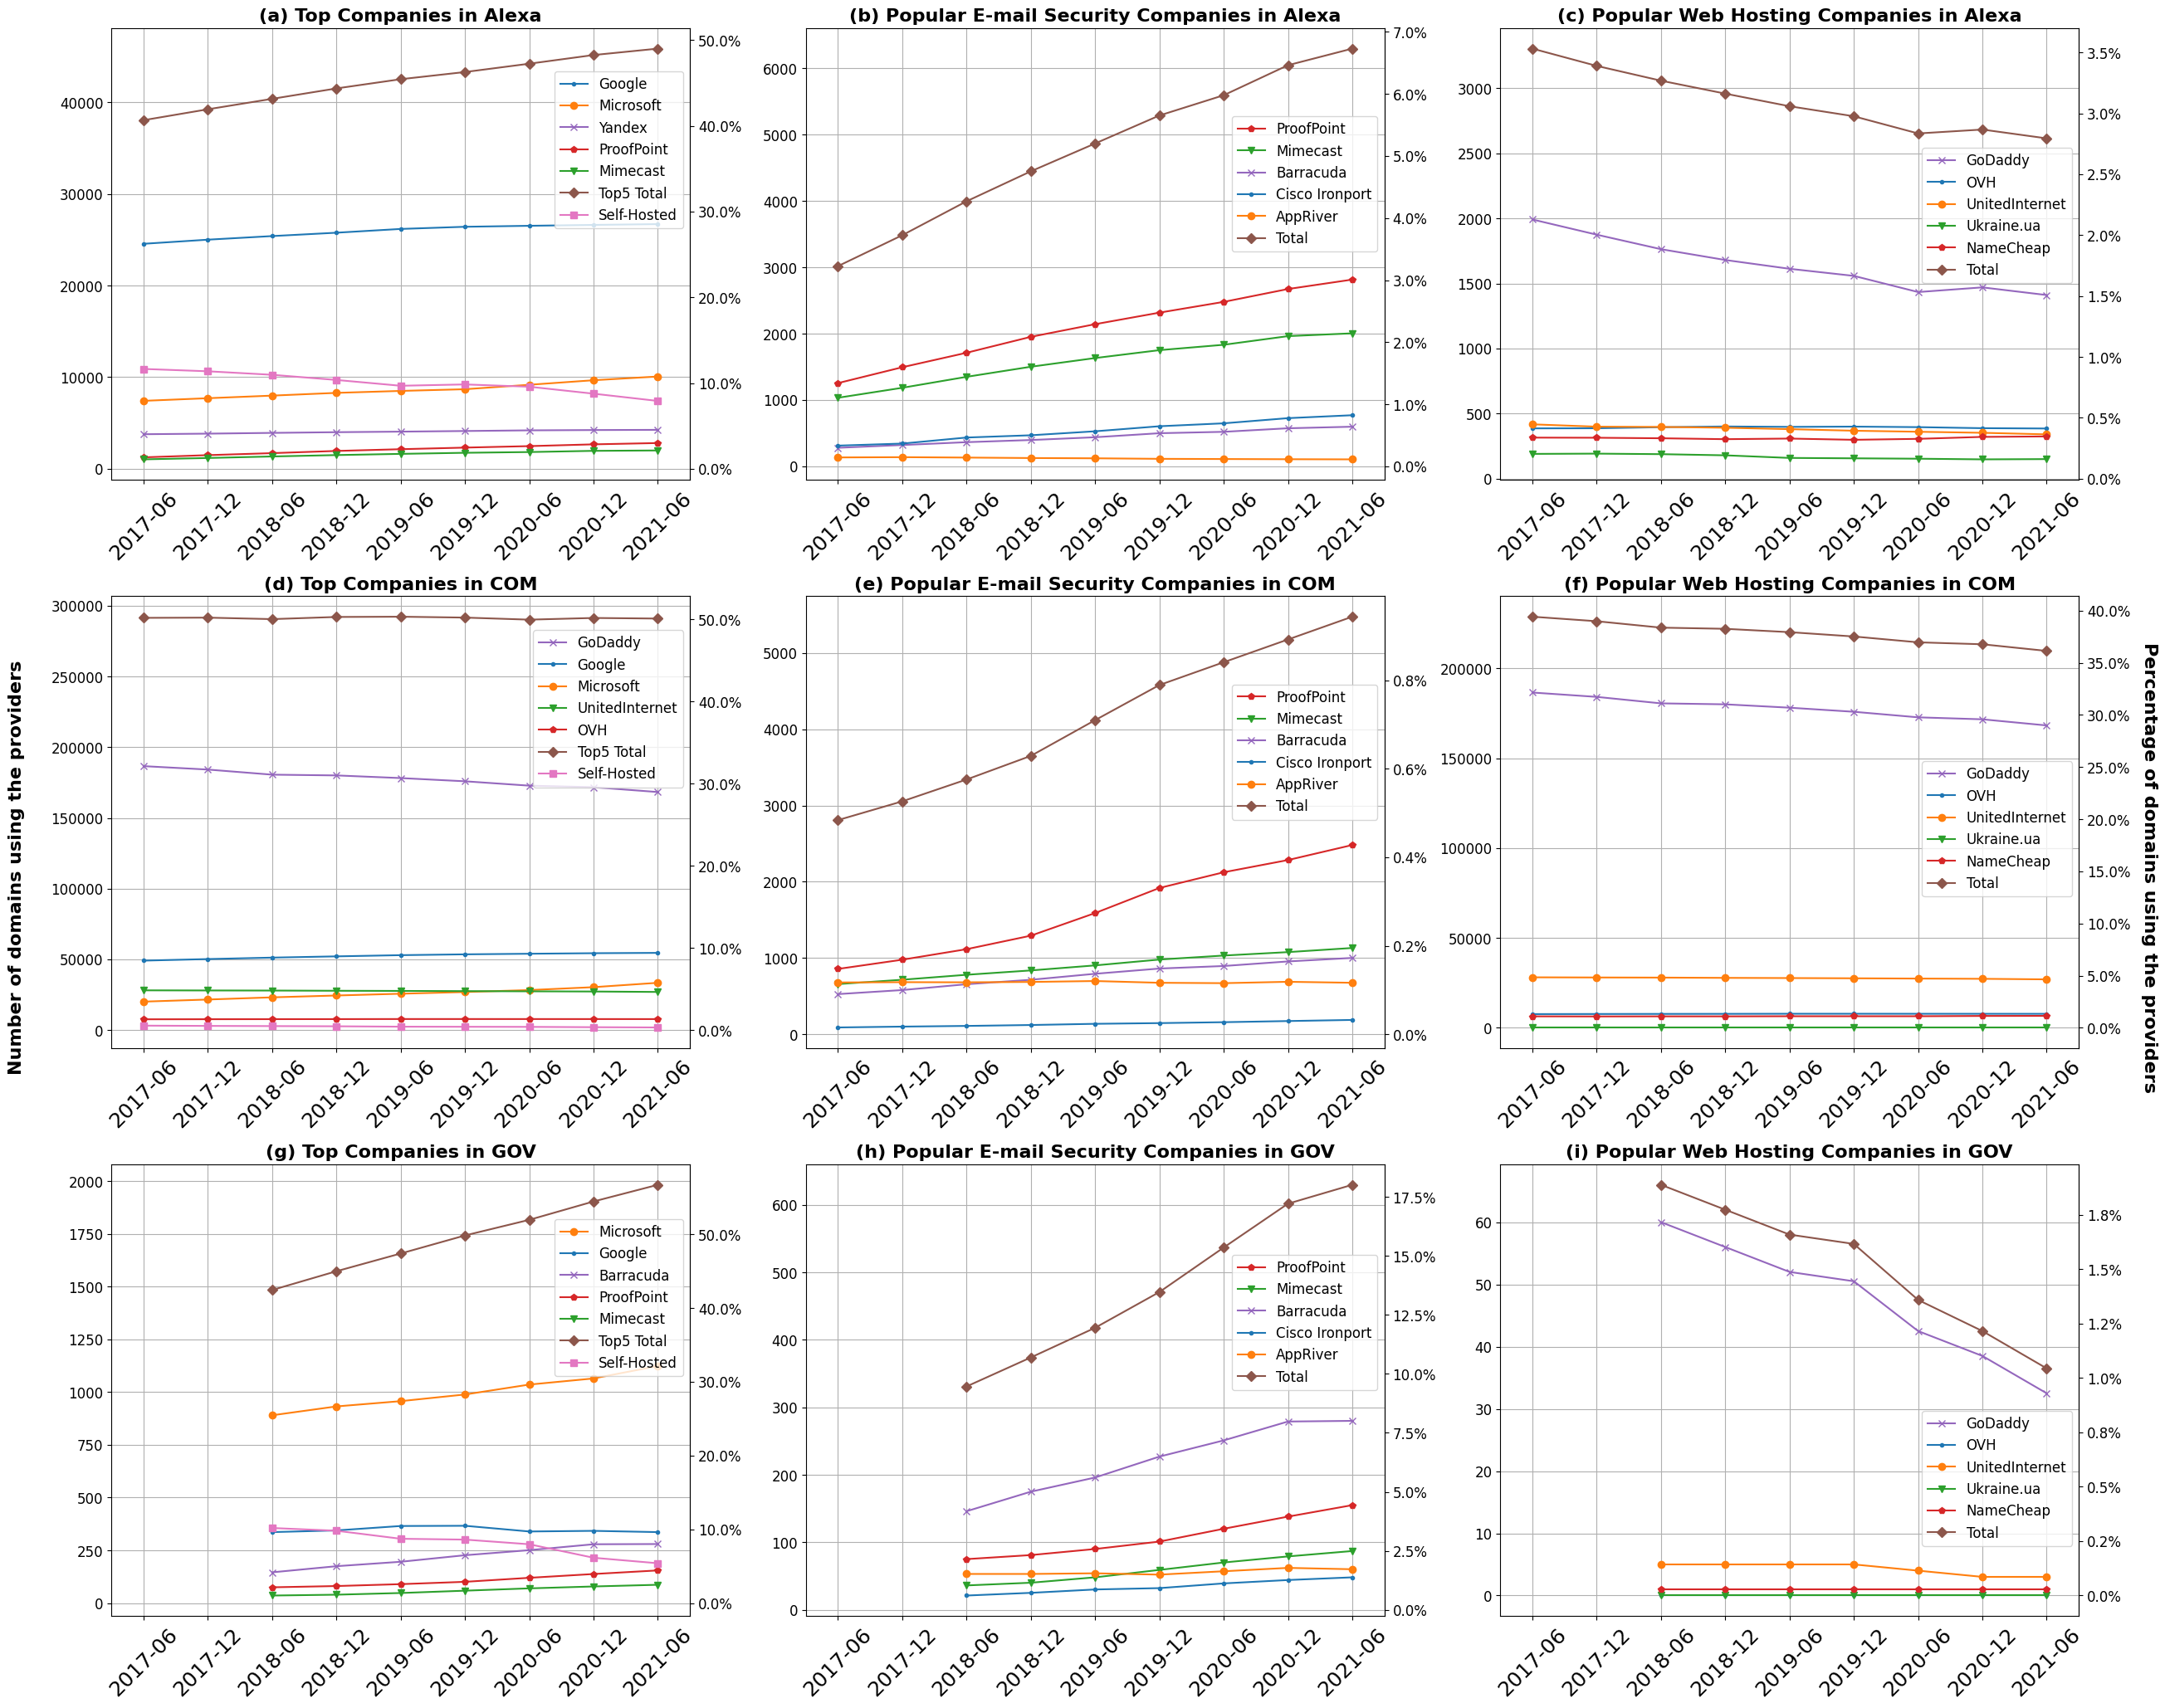


EXPORTING ALL COMPANY DATA TO CSV


Reading all company data from: ./data/cr_output_cr_common_old_certs_2021-06-08_0914
MX Type: common, Date: 2021-06-08
Total domains with active and properly-configured mail servers: 93,538

Total unique provider IDs found: 14274
Note that one company can own multiple provider IDs.
We split 1 credit if multiple primary MX records exist.

TOP 10 PROVIDERS for common on 2021-06-08
Rank   Provider                                 Domains that Use This Provider
--------------------------------------------------------------------------------
1      Google                                         26,696.67
2      Microsoft                                      10,072.33
3      Yandex                                          4,253.08
4      ProofPoint                                      2,814.67
5      Mimecast                                        2,005.00
6      GoDaddy                                         1,410.75
7      Zoho                           

<Figure size 640x480 with 0 Axes>

In [6]:
if __name__ == "__main__":
    # Main Execution
    FIG, AXES = plt.subplots(3, 3, figsize=(26, 21), sharex=False)

    ttl_num_domains = {
        'common': [93538] * 9,
        'com_common': [580537] * 9,
        'gov_common': [3496] * 9,
    }
    
    version_info = "0914"
    
    gen_all_graphs(ttl_num_domains, version_info)
    plt.tight_layout(rect=[0.015, 0.015, 0.99, 1])
    
    FIG.text(0.001, 0.5, 'Number of domains using the providers', 
            va='center', rotation='vertical', fontweight='bold', fontsize=16)
    FIG.text(0.989, 0.5, 'Percentage of domains using the providers',
            va='center', rotation=-90, fontweight='bold', fontsize=16)
    plt.savefig(f'{OUTPUT_PATH}/trends_combined.pdf', format='pdf')
    plt.show()
    plt.clf()

    # Export all company data to CSV for the latest date
    print("\n" + "="*80)
    print("EXPORTING ALL COMPANY DATA TO CSV")
    print("="*80 + "\n")
    
    date_specified = "2021-06-08"
    for mx_type in ["common", "com_common", "gov_common"]:
        all_data = read_all_company_data(mx_type, date_specified, version_info, ttl_num_domains)
        print()